In [7]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.signal import hilbert

import tinyDA as tda
import umbridge

use_saveddata = True
max_shift  = 12

# Generate sythetic data

## Read saved datas

In [8]:
# Instead of running umbridge: open the savef d_true
if use_saveddata:
    with open('d_true_20s.npy', 'rb') as f:
        d_true = np.load(f)
    ny = len(d_true)
    print(ny)

    n_sensors = 2

402


## Generate new synthetic data
If you want to change something in the pysical setup (e.g. sensors location), you need to rerun this part together with the terra DG server.

In [9]:
if not use_saveddata:
    # Set all simu parameters 
    # Set domain size and simulation time: this info is shared between the forward and parameter models 
    Lx = 20
    Lz = 1 
    TEnd = 10 
    H = 1.5


    # Create the config data
    #### Change captor location and number
    # Each element of the list "captors" is a tuple of (x,z) coordinates. 
    # Coordinates are given in the (scaled) domain: x \in [0, grid_size_x], z \in [0, grid_size_y]
    sensors = [(4,0.8), (13.5, 0.6)]
    # sensors = [(2,0.), (0, 1)]

    # Create sorted sensor list to pass to the forward model: do not change this part 
    sensors_sort = np.array(sensors, dtype=[('x',float),('y',float)])
    sensors_sort = np.sort(sensors_sort, order=['x','y'])
    sensors = sensors_sort.tolist()
    n_sensors = len(sensors)
    print("Number of pressure sensors:", n_sensors)

    # connect to the UM-Bridge model.
    umbridge_model = umbridge.HTTPModel('http://localhost:4242', "forward")

    # wrap the UM-Bridge model in the tinyDA UM-Bridge interface.
    config={"captors":sensors}
    my_model = tda.UmBridgeModel(umbridge_model, umbridge_config=config)

In [10]:
if not use_saveddata:
    # Informations relative to the parameter model
    # Set in the jl server: 
    # - number of points to describe the level set passed to the forward model = nx
    # - number of points to describe all pressure time series given by the forward model = ny
    nx = umbridge_model.get_input_sizes(config)[0] #the input is the value of f(x) at each grid point
    ny = umbridge_model.get_output_sizes(config)[0] #the outout is a time series of the pressure

    print(f"input:{nx}, output:{ny}")

In [11]:
if not use_saveddata:
    # Generate synthetic data
    exact = np.zeros(nx)

    # True source in the middle of the domain 
    idx_middle = int(nx/2)
    source_width = 4 # in length unit 
    idx_width = int(0.5 * source_width / Lx * nx )
    exact[idx_middle - idx_width : idx_middle + idx_width]=1
    d_true = my_model(exact)

    # add some noise to the model output
    # d = d_true + np.random.normal(loc=0, scale=sigma_noise, size=ny)

In [12]:
if not use_saveddata:
    # Save the new data
    with open('d_true.npy', 'wb') as f:
        np.save(f, d_true)

## Show pressure outputs
plt.plot(d_true[0::n_sensors])
plt.show()
plt.plot(d_true[1::n_sensors])

<Figure size 640x480 with 1 Axes>

# Set up log-likelihood

Test standard Gaussian log-likelihood:
$$\log ⁡L(x)=-0.5(x-y)^T\Sigma^{-1}(x−y)$$

with a Wasserstein-2-based log-likelihood as in Dunlop+Yang, 2021:
$$\log ⁡L(x)\propto -\lambda W_2(x,y),$$

where:
- x = model output
- y = ground truth

with an applied scaling $\sigma(x)$

While $W_1$ is contained in scipy.stats it seems $W_2$ is not

In [53]:
def sigma_linear(v, b): 
    if np.min(v) + b < 0:
        raise ValueError("b too small: scaled signal is negative")
    return v + b

def sigma_signsensitive(v, b):
    pos = v >= 0
    raw = np.empty_like(v)
    raw[pos] = v[pos] + 1.0 / b
    raw[~pos] = (1.0 / b) * np.exp(b * v[~pos])
    return raw

def sigma_softplus(v, b):
    return np.logaddexp(0.0, b * v)

def sigma_envelope_exp(v, b):
    env = np.abs(hilbert(v))
    return np.exp(b * env)

class WassersteinLoglike:
    """Wasserstein log-likelihood.
    `sigma` is a scaling function"""

    def __init__(self, data, sigma, lam=1.0, b=1.0, n_quantiles=200):
        self.data = np.asarray(data, dtype=float).ravel()
        self.sigma = sigma
        self.lam = lam
        self.b = b
        self.n_quantiles = n_quantiles

    def _density(self, x):
        raw = self.sigma(x, self.b)
        return raw / raw.sum()

    def _quantile_function(self, density):
        cdf = np.cumsum(density); cdf = cdf / cdf[-1]
        t = np.arange(len(density), dtype=float)
        u = (np.arange(self.n_quantiles) + 0.5) / self.n_quantiles
        return np.interp(u, cdf, t)

    def loglike(self, x):
        x = np.asarray(x, dtype=float).ravel()
        try:
            p, q = self._density(x), self._density(self.data)
        except ValueError:
            return -np.inf    # likelihood 0: the scaling is not valid for this signal
        Fx, Fd = self._quantile_function(p), self._quantile_function(q)
        #plt.plot(Fx-Fd)
        #plt.show()
        return -self.lam * np.sum((Fx - Fd) ** 2) / self.n_quantiles

class MultiSensorLoglike:
    """likelihoods: a list of length n_sensors likelihoods, each already
    constructed with its own sensor's reference data."""
    def __init__(self, likelihoods, n_sensors):
        self.likelihoods = likelihoods
        self.n_sensors = n_sensors

    def loglike(self, x):
        x = np.asarray(x, dtype=float).ravel()   # <- use the argument, not a stored copy
        return sum(like.loglike(x[i::self.n_sensors]) for i, like in enumerate(self.likelihoods)) 


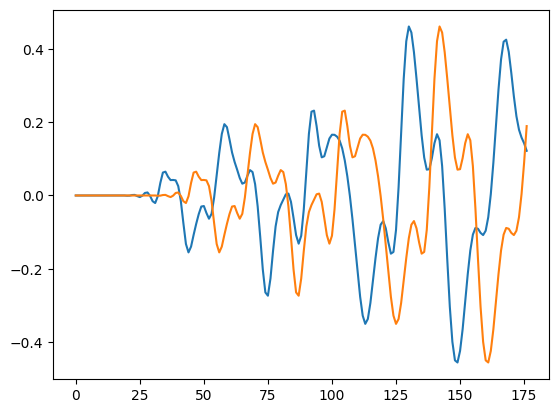

In [54]:
# Define the "forward map" for the 1D model: shift the pressure recordings. 
# Note that the shift is an integer value, to avoid interpolation. 

def shift_per_sensor(flat_signal, shift, n_sensors):
    flat_signal = np.asarray(flat_signal, dtype=float).ravel()
    parts = [np.roll(flat_signal[i::n_sensors], shift) for i in range(n_sensors)]
    out = np.empty_like(flat_signal)
    for i, p in enumerate(parts):
        out[i::n_sensors] = p
    return out

# LS: function to cut the signal to left and right for a natural shifting later
def trim_signal(flat_signal, max_shift):
    flat_signal = np.asarray(flat_signal, dtype=float).ravel()
    return flat_signal[max_shift:-max_shift]

def shift_and_trim(flat_signal, shift, n_sensors, max_shift):
    shifted = shift_per_sensor(flat_signal, shift, n_sensors)
    return trim_signal(shifted, max_shift)

d_true_cut = shift_and_trim(d_true, 0, n_sensors, 2 * max_shift)
shifted_test_cut = shift_and_trim(d_true, max_shift, n_sensors, 2*max_shift)
plt.plot(d_true_cut[0::n_sensors])
plt.plot(shifted_test_cut[0::n_sensors])

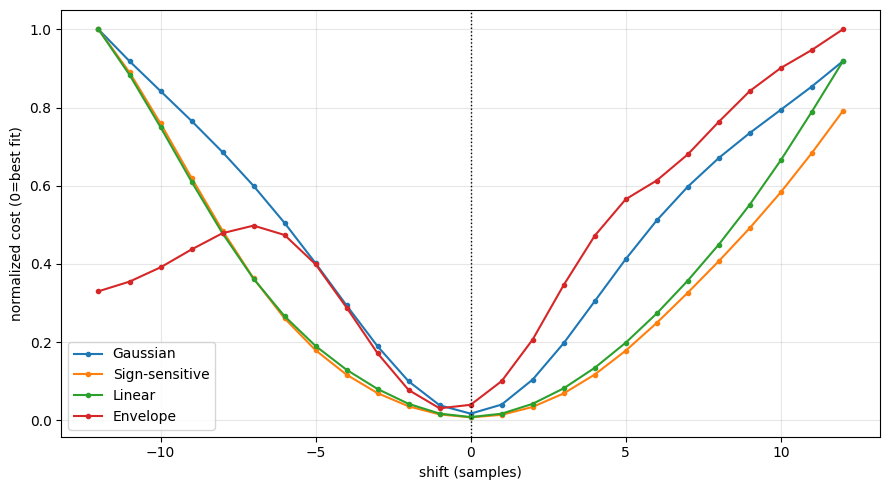

'\nfig, ax = plt.subplots(figsize=(9, 5))\nfor name, like in likelihoods.items():\n    vals = np.array([like.loglike(shift_and_trim(d_true, s, n_sensors, 2*max_shift)) for s in shifts])\n    ax.plot(shifts, np.exp(vals), label=name, marker=\'.\')\nax.axvline(0, color=\'k\', ls=\':\', lw=1)\nax.set_xlabel("shift (samples)")\nax.set_ylabel("exp(loglike) ")\nax.legend(); ax.grid(alpha=0.3)\nplt.tight_layout(); plt.show()\n'

In [64]:
# LS Trim also true data
data_trimmed = trim_signal(d_true, 2*max_shift)
# LS add noise to see its effect
sigma_noise = 0.05
data_trimmed_noisy = data_trimmed + np.random.normal(loc=0, scale=sigma_noise, size=len(data_trimmed)) # LS to add noise

## Shows the loss (=-loglike) for some values of b
## Those are NOT the scaling used for the plots in the next cells. The values of b and lambda will be different.
# Test for Gaussian log like
cov_likelihood = sigma_noise**2*np.eye(data_trimmed.shape[0])
my_loglike_gaussian = tda.GaussianLogLike(data_trimmed_noisy, cov_likelihood)

# Test for Wasserstain based log like
# TODO move implementation into tinyDA
lam = sigma_noise * sigma_noise
# sign_sensitive scaling
my_loglike = MultiSensorLoglike(likelihoods=[
    WassersteinLoglike(data_trimmed_noisy[0::n_sensors], sigma_signsensitive, lam=lam, b=0.1),    # b standard value:100
    WassersteinLoglike(data_trimmed_noisy[1::n_sensors], sigma_signsensitive, lam=lam, b=0.1),    # b standard value:1
], n_sensors=2)

# linear scaling
my_loglike_linear = MultiSensorLoglike(likelihoods=[
    WassersteinLoglike(data_trimmed_noisy[0::n_sensors], sigma_linear, lam=lam, b=1.1), # b standard value:0.1 # LS: changed because b was too small to get positive signal
    WassersteinLoglike(data_trimmed_noisy[1::n_sensors], sigma_linear, lam=lam, b=1.1), # b standard value:1.1
], n_sensors=2)

# hilbert envelop scaling
my_loglike_envelope = MultiSensorLoglike(likelihoods=[
    WassersteinLoglike(data_trimmed_noisy[0::n_sensors], sigma_envelope_exp, lam=lam, b=0.1),   # b standard value:15
    WassersteinLoglike(data_trimmed_noisy[1::n_sensors], sigma_envelope_exp, lam=lam, b=0.1),    # b standard value:5
], n_sensors=2)


likelihoods = {
    "Gaussian": my_loglike_gaussian,
    "Sign-sensitive": my_loglike,
    "Linear": my_loglike_linear,
    "Envelope": my_loglike_envelope,
}

shifts = np.arange(-max_shift, max_shift+1) #HERE 
fig, ax = plt.subplots(figsize=(9, 5))

# To plot vertical difference for Gaussian loglike
#trimmed_shift = shift_and_trim(d_true, shifts[0], n_sensors, 2*max_shift)
#plt.plot(data_trimmed_noisy[0::n_sensors]- trimmed_shift[0::n_sensors])
#plt.show()
#plt.plot(data_trimmed_noisy[1::n_sensors]- trimmed_shift[1::n_sensors])
#plt.show()
for name, like in likelihoods.items():
    vals = np.array([-like.loglike(shift_and_trim(d_true, s, n_sensors, 2*max_shift)) for s in shifts])
    ax.plot(shifts, vals / (vals.max() or 1), label=name, marker='.')
ax.axvline(0, color='k', ls=':', lw=1)
ax.set_xlabel("shift (samples)")
ax.set_ylabel("normalized cost (0=best fit)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
"""
fig, ax = plt.subplots(figsize=(9, 5))
for name, like in likelihoods.items():
    vals = np.array([like.loglike(shift_and_trim(d_true, s, n_sensors, 2*max_shift)) for s in shifts])
    ax.plot(shifts, np.exp(vals), label=name, marker='.')
ax.axvline(0, color='k', ls=':', lw=1)
ax.set_xlabel("shift (samples)")
ax.set_ylabel("exp(loglike) ")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
"""

## Computing the marginals 

In [67]:
# Integration using Simpson integration 
from scipy.integrate import simpson

# Number of integration samples: 61. LS: I think 60 (no endpoint)
shifts = np.arange(-max_shift, max_shift + 1)

# Integration routine 
def marginal_likelihood(sigma, lam, b, d_):
    # Possible sigma:
    # sigma_linear
    # sigma_signsensitive
    # sigma_softplus
    # sigma_envelope_exp

    d_trimmed = trim_signal(d_, 2*max_shift)
    my_loglike = MultiSensorLoglike(likelihoods=[ # HERE
        WassersteinLoglike(d_trimmed[0::n_sensors], sigma, lam=lam, b=b),
        WassersteinLoglike(d_trimmed[1::n_sensors], sigma, lam=lam, b=b),
    ], n_sensors=n_sensors)
    vals = np.array([my_loglike.loglike(shift_and_trim(d_, s, n_sensors, 2*max_shift)) for s in shifts]) 
    exp_vals = np.exp(vals)
    return np.sum(exp_vals) #In principle we should multiply by 1/60 but since this is a constant factor for all marginal loglike, it will not change which b is best  
            #simpson(exp_vals, shifts)


sigmas = {
    "Linear": sigma_linear,
    "Sign-sensitive": sigma_signsensitive,
    "sigma_softplus": sigma_softplus,
    "Envelope": sigma_envelope_exp,
}

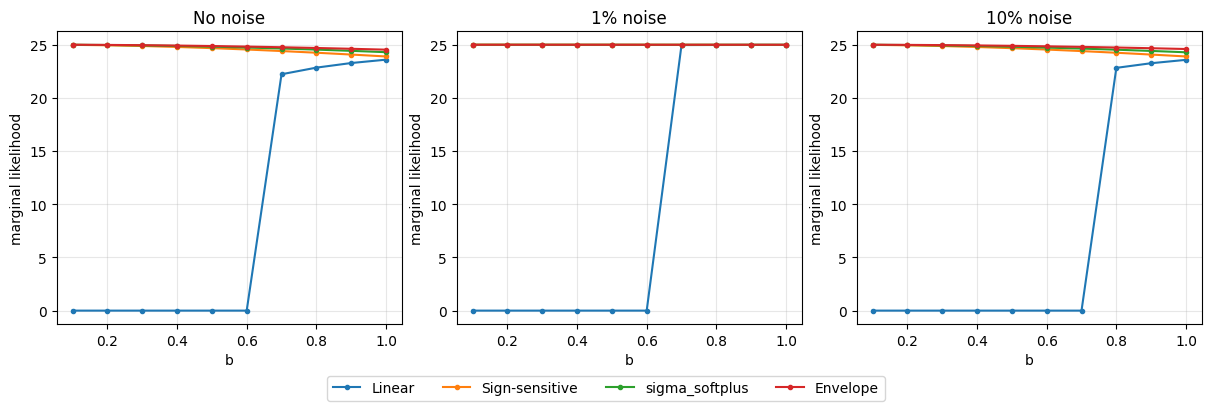

In [ ]:
# Plot the marginals as function of b with various noise levels
fig, ax = plt.subplots(1, 3, figsize=(12, 4), layout='constrained')
array_b = np.linspace(0.1, 1, num=10)


### Marginals for the sythetic signal with no noise as reference
lam = 0.01 # this value should not matter for which b is better 
for name, scaling in sigmas.items():
    margs = [marginal_likelihood(sigma=scaling, lam=lam, b=b, d_=d_true) for b in array_b]
    ax[0].plot(array_b, margs,  marker='.')
    ax[0].set_title("No noise")


# Marginals for the sythetic signal with 1% noise
sigma_noise = 0.01 # NOTE: the reason for the plot is that the posterior is much more concentrated in this case
lam = sigma_noise**2 
d = d_true + np.random.normal(loc=0, scale=sigma_noise, size=ny)
for name, scaling in sigmas.items():
    margs = [marginal_likelihood(scaling, lam, b, d) for b in array_b]
    ax[1].plot(array_b, margs,marker='.')
    ax[1].set_title("1% noise")


# Marginals for the sythetic signal with 10% noise
sigma_noise = 0.1
lam = sigma_noise**2 # here same lam as in the noiseless case
d = d_true + np.random.normal(loc=0, scale=sigma_noise, size=ny)
for name, scaling in sigmas.items():
    margs = [marginal_likelihood(scaling, lam, b, d) for b in array_b]
    ax[2].plot(array_b, margs, label=name, marker='.')
    ax[2].set_title("10% noise")



for ax_ in ax:
    ax_.set_xlabel("b")
    ax_.set_ylabel("marginal likelihood")
    ax_.grid(alpha=0.3)
fig.legend(loc="outside lower center", ncols = 4)

# LS notes (to discuss): 
#  Introduced error handling for linear shift
#  Introduced max shift and trimming 
#  I am not sure a single b for all sensor is good. However, one b per sensor increases a lot number of hyperparameters
#  With max shift and trimming, the loglikelihoods in this case seem quite insensitive to the value of b
# I DON'T THINK MAXIMIZING loglike it what we want. We want to have the least oscillatory loglike possible
#  NOTE: envelope behaves weirdly for max_shift= 15, 20, but since we trim 2*max_shift, there's also very little signal remaining, so the loglikelihoods are not very informative.

From Claude 

(on empirical Bayes, here \lambda is the hyperparameter, b for us): Normalization. The likelihood must be properly normalized in y for every λ. If λ changes the normalizing constant (e.g., a dispersion parameter), that term must be included, or the evidence comparison is meaningless.

A practical workflow
Ask whether λ is “real”. If it is part of a sensible generative model, go fully Bayesian (method 1). This is usually the best default with modern HMC (Stan, PyMC, NumPyro).
If full Bayes is too expensive (large GPs, deep models), use type-II maximum likelihood, and sanity-check λ̂ against a coarse grid or profile.
If λ exists to fix misspecification or robustness (tempering, robust-loss scales), tune it with PSIS-LOO or K-fold CV, or with a calibration criterion.
Always validate. Use posterior predictive checks, and simulation-based calibration (Talts et al.) if you want to confirm the whole procedure recovers known values on simulated data.
Report sensitivity. Show how the key posterior quantities change across plausible λ values. If they barely move, the tuning choice matters little.

Why the standard Bayesian tools don’t apply

Your “likelihood” is presumably something like

$$L_c(\theta) \propto \exp\!\left(-\frac{W_2^2(\sigma_c(d),\, \sigma_c(F(\theta)))}{2s^2}\right).$$

This is not a normalized density in the data d, and its scale depends on c. So:

No prior on c, no evidence maximization. The “evidence” for different c values isn’t comparable. Even the effective data space changes with c, so this is a generalized-Bayes (Gibbs) posterior, not a likelihood-based one.

No predictive comparison in the c-dependent loss. Comparing LOO or held-out W₂ scores across c compares different yardsticks.

c and the temperature s are coupled. Changing c changes the typical magnitude of W₂², so a fixed s means a different effective posterior sharpness for each c. You can’t tune c without retuning s.

So with exp(−W₂²/2s²), each c gives a posterior with a different, arbitrary sharpness. When you then compare c values, a c can look “better” simply because its posterior happens to be wider (better coverage) or narrower (smaller error around a good mode), not because it handles noise better.